<a href="https://colab.research.google.com/github/mmariannaholanda/ia_identificacao_tumores/blob/main/treino_redeneural_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# etapa 1 - importar banco de dados e bibliotecas
import pandas as pd
import numpy as np

np.random.seed(42) # *semente* fixa o ponto de partida do sorteador pra que toda vida tenha a mesma sequencia

dados = pd.read_csv("tumores.csv")


#print(dados.head())
# dados.head() = mostra as 5 primeiras linhas da tabela por padrão.

print(dados.shape)
# shape = retorna as dimensões da tabela; primeiro valor = quantidade de linhas; segundo valor = quantidade de colunas.

(569, 6)


In [3]:
# separando teste de treino
# uso pandas para filtras a tabela original e criar outras para fazer a separacao
treino = dados[dados.iloc[:, 5] == "treino"]
# iloc[:, 5] = seleciona todas as linhas da 6ª coluna; == "treino" = filtra apenas as linhas com esse valor; treino = armazena a tabela filtrada.

teste = dados[dados.iloc[:, 5] == "teste"]
# == "teste" = filtra apenas as linhas com esse valor; teste = armazena a tabela filtrada.


print(treino.shape)
print(teste.shape)
print(treino.head())
print(teste.head())




(455, 6)
(114, 6)
   raio_medio  textura_media  suavidade_media  pontos_concavos_medio  \
0       17.99          10.38          0.11840                 0.1471   
2       19.69          21.25          0.10960                 0.1279   
3       11.42          20.38          0.14250                 0.1052   
4       20.29          14.34          0.10030                 0.1043   
6       18.25          19.98          0.09463                 0.0740   

   B_maligno conjunto  
0          1   treino  
2          1   treino  
3          1   treino  
4          1   treino  
6          1   treino  
    raio_medio  textura_media  suavidade_media  pontos_concavos_medio  \
1        20.57          17.77          0.08474                0.07017   
5        12.45          15.70          0.12780                0.08089   
10       16.02          23.24          0.08206                0.03323   
13       15.85          23.95          0.08401                0.05364   
15       14.54          27.54          0

In [4]:
# pre processamento de dados em ML
# fazer com que as 4 características dos tumores tenham escalas comparáveis

media = treino.iloc[:, 0:4].mean()
# mean() = calcula a média de cada coluna; iloc[:, 0:4] = seleciona todas as linhas e as 4 primeiras colunas.

desvio = treino.iloc[:, 0:4].std()
# std() = calcula o desvio padrão de cada coluna usando os dados de treino.


# Standardization
treino_padronizado = (treino.iloc[:, 0:4] - media) / desvio
teste_padronizado = (teste.iloc[:, 0:4] - media) / desvio


# baseline
# tem a classe benigno e amigno, vamos ver qual aparece mais
print(treino["B_maligno"].value_counts())
classe_majoritaria = treino["B_maligno"].mode()[0]
# mode() = encontra o valor que mais aparece na coluna; [0] = acessa a primeira moda encontrada; classe_majoritaria = armazena esse valor.
previsoes = [classe_majoritaria] * len(teste)
# [classe_majoritaria] = cria uma lista com a classe 0; len(teste) = quantidade de registros de teste; * = repete a classe 0 para todos os registros.
from sklearn.metrics import accuracy_score  # Importa accuracy_score, função que calcula a proporção de previsões corretas.
baseline = accuracy_score(teste["B_maligno"], previsoes)  # Compara as classificações reais do teste com as previsões criadas.
print(baseline)  # Exibe a acurácia da baseline.
# ficou igual a 63,2%

B_maligno
0    285
1    170
Name: count, dtype: int64
0.631578947368421


In [5]:
# montando a base de ref da rede
entradas_treino = treino_padronizado[['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']].values
respostas_treino = treino['B_maligno'].values.reshape(-1, 1)   # .vslues transforma em array
# como acessar? X[0][0] a 1- primeira caracteristica 2- primeira linha= xn  y[0] - 1- xn

# o teste usa o mesmo formato (padronizado com a média e o desvio do treino)
entradas_teste = teste_padronizado[['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']].values
respostas_teste = teste['B_maligno'].values.reshape(-1, 1)

# arquitetura
quantidade_entradas = 4
quantidade_neuronios_escondidos = 8
quantidade_neuronios_saida = 1

# outras variaveis
taxa_aprendizado = 0.1
quantidade_passos = 5000  # qntd de epocas


# pesos e bias
pesos_escondida = np.random.randn(quantidade_entradas, quantidade_neuronios_escondidos) * np.sqrt(2/quantidade_entradas)
 # pesos_escondida = matriz de pesos da primeira camada;
 # np.random.randn() = gera valores aleatórios com distribuição normal;
 # np.sqrt() = calcula a raiz quadrada; 2/quantidade_entradas = fator de escala He para inicialização dos pesos.

vies_escondida = np.zeros((1, quantidade_neuronios_escondidos))    # 1 bias por neuronio
# np.zeros() = cria uma matriz preenchida com zeros; (1, quantidade_neuronios_escondidos) = define 1 linha e 8 colunas.

pesos_saida = np.random.randn(quantidade_neuronios_escondidos, quantidade_neuronios_saida) * np.sqrt(1/quantidade_neuronios_escondidos)

vies_saida = np.zeros((1, quantidade_neuronios_saida))



# formulas
def relu(x):  # transforma os valores negativos em zero e mantém os positivos
    return np.maximum(0, x)

def sigmoide(x): # transforma o resultado em uma probabilidade entre 0 e 1
    return 1 / (1 + np.exp(-x))


def calcular_perda(respostas, probabilidades):
    epsilon = 1e-7

    probabilidades = np.clip(probabilidades, epsilon, 1-epsilon)

    perda = -np.mean(
        respostas * np.log(probabilidades) +
        (1-respostas) * np.log(1-probabilidades)
    )

    return perda



def propagar(entradas, pesos_escondida, vies_escondida, pesos_saida, vies_saida):

    # @ representa a multiplicação de matrizes
    soma_escondida = entradas @ pesos_escondida + vies_escondida       # Combinação dos pesos e entradas
    ativacao_escondida = relu(soma_escondida)          # Ativação da camada escondida

    soma_saida = ativacao_escondida @ pesos_saida + vies_saida      # Combinação para a saída
    probabilidades = sigmoide(soma_saida)  # Probabilidade final

    return probabilidades, soma_escondida, ativacao_escondida  # devolve o resultado previsto (probabilidades), a soma antes da ReLU e a saida da escondida (ativacao_escondida)


def calcular_gradientes(entradas, respostas, probabilidades, soma_escondida, ativacao_escondida, pesos_saida):

    quantidade_amostras = entradas.shape[0]

    # Gradientes da camada de saída (começa por aqui, de trás para frente)
    erro_saida = (probabilidades - respostas) / quantidade_amostras

    grad_pesos_saida = ativacao_escondida.T @ erro_saida

    grad_vies_saida = np.sum(erro_saida, axis=0, keepdims=True)

    # Gradientes da camada escondida
    grad_ativacao_escondida = erro_saida @ pesos_saida.T

    erro_escondida = grad_ativacao_escondida * (soma_escondida > 0)

    grad_pesos_escondida = entradas.T @ erro_escondida

    grad_vies_escondida = np.sum(erro_escondida, axis=0, keepdims=True)


    return grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida


def atualizar_parametros(pesos_escondida, vies_escondida, pesos_saida, vies_saida,
                         grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida,
                         taxa_aprendizado):

    pesos_escondida = pesos_escondida - taxa_aprendizado * grad_pesos_escondida
    vies_escondida = vies_escondida - taxa_aprendizado * grad_vies_escondida

    pesos_saida = pesos_saida - taxa_aprendizado * grad_pesos_saida
    vies_saida = vies_saida - taxa_aprendizado * grad_vies_saida

    return pesos_escondida, vies_escondida, pesos_saida, vies_saida

dados.info()
# info() = apresenta informações estruturais da tabela, como nomes das colunas, quantidade de valores não nulos e tipos de dados.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   raio_medio             569 non-null    float64
 1   textura_media          569 non-null    float64
 2   suavidade_media        569 non-null    float64
 3   pontos_concavos_medio  569 non-null    float64
 4   B_maligno              569 non-null    int64  
 5   conjunto               569 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 26.8+ KB


In [6]:
# comecando o laco de treino
# etapa final - laço de treino
historico_perda = []   # lista vazia para guardar a perda de cada passo

for passo in range(quantidade_passos):

    # 1) propagar: calcula as probabilidades com os pesos atuais
    probabilidades, soma_escondida, ativacao_escondida = propagar(
        entradas_treino, pesos_escondida, vies_escondida, pesos_saida, vies_saida
    )

    # 2) perda: mede o erro e guarda
    perda = calcular_perda(respostas_treino, probabilidades)
    historico_perda.append(perda)

    # 3) gradientes: quanto mudar cada peso
    (grad_pesos_escondida, grad_vies_escondida,
     grad_pesos_saida, grad_vies_saida) = calcular_gradientes(
        entradas_treino, respostas_treino, probabilidades,
        soma_escondida, ativacao_escondida, pesos_saida
    )

    # 4) atualizar: guarda os novos pesos nas mesmas variáveis
    pesos_escondida, vies_escondida, pesos_saida, vies_saida = atualizar_parametros(
        pesos_escondida, vies_escondida, pesos_saida, vies_saida,
        grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida,
        taxa_aprendizado
    )

    if passo % 100 == 0:
        print(f"passo {passo}: perda = {perda:.4f}")

print(f"perda final: {historico_perda[-1]:.4f}")



passo 0: perda = 0.6882
passo 100: perda = 0.1946
passo 200: perda = 0.1565
passo 300: perda = 0.1491
passo 400: perda = 0.1462
passo 500: perda = 0.1444
passo 600: perda = 0.1423
passo 700: perda = 0.1396
passo 800: perda = 0.1379
passo 900: perda = 0.1367
passo 1000: perda = 0.1358
passo 1100: perda = 0.1349
passo 1200: perda = 0.1341
passo 1300: perda = 0.1334
passo 1400: perda = 0.1329
passo 1500: perda = 0.1323
passo 1600: perda = 0.1318
passo 1700: perda = 0.1314
passo 1800: perda = 0.1310
passo 1900: perda = 0.1307
passo 2000: perda = 0.1304
passo 2100: perda = 0.1301
passo 2200: perda = 0.1298
passo 2300: perda = 0.1296
passo 2400: perda = 0.1293
passo 2500: perda = 0.1290
passo 2600: perda = 0.1287
passo 2700: perda = 0.1284
passo 2800: perda = 0.1281
passo 2900: perda = 0.1279
passo 3000: perda = 0.1276
passo 3100: perda = 0.1273
passo 3200: perda = 0.1270
passo 3300: perda = 0.1267
passo 3400: perda = 0.1264
passo 3500: perda = 0.1261
passo 3600: perda = 0.1258
passo 3700: p

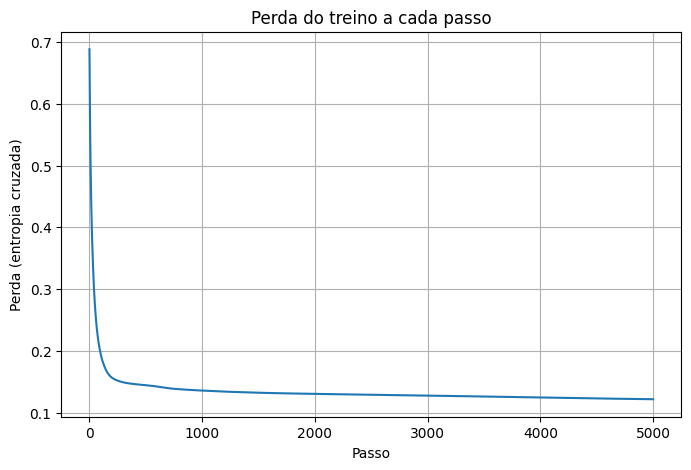

In [12]:
# gráfico da perda
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(historico_perda)
plt.xlabel("Passo")
plt.ylabel("Perda (entropia cruzada)")
plt.title("Perda do treino a cada passo")
plt.grid(True)

plt.savefig("perda_treino.png", dpi=150, bbox_inches="tight")


plt.show()


In [8]:
# acuracia
# transformar cada probabilidade em uma decisao
# COMPARAR COM A DECISAO REAL E GUARDAR QUANTAS VEZES ACERTOU


probabilidades_treino, _, _ = propagar(
    entradas_treino, pesos_escondida, vies_escondida, pesos_saida, vies_saida
)
previsoes_treino = (probabilidades_treino > 0.5).astype(int)   # True vira 1 e False vira 0
acuracia_treino = np.mean(previsoes_treino == respostas_treino)

# no teste (dados que a rede nunca viu)
probabilidades_teste, _, _ = propagar(
    entradas_teste, pesos_escondida, vies_escondida, pesos_saida, vies_saida
)
previsoes_teste = (probabilidades_teste > 0.5).astype(int)
acuracia_teste = np.mean(previsoes_teste == respostas_teste)

print(f"Acurácia no treino: {acuracia_treino:.3f}")
print(f"Acurácia no teste:  {acuracia_teste:.3f}")
print(f"Baseline (sempre benigno): {baseline:.3f}")
print(f"Ganho sobre o baseline: {acuracia_teste - baseline:.3f}")


Acurácia no treino: 0.941
Acurácia no teste:  0.956
Baseline (sempre benigno): 0.632
Ganho sobre o baseline: 0.325


In [9]:
# aqui eu faço o recall:

verdadeiros_positivos = np.sum((previsoes_teste == 1) & (respostas_teste == 1))
falsos_negativos = np.sum((previsoes_teste == 0) & (respostas_teste == 1))
falsos_positivos = np.sum((previsoes_teste == 1) & (respostas_teste == 0))
verdadeiros_negativos = np.sum((previsoes_teste == 0) & (respostas_teste == 0))

recall_maligno = verdadeiros_positivos / (verdadeiros_positivos + falsos_negativos)

print(f"Verdadeiros positivos: {verdadeiros_positivos}")
print(f"Falsos negativos: {falsos_negativos}")
print(f"Falsos positivos: {falsos_positivos}")
print(f"Verdadeiros negativos: {verdadeiros_negativos}")
print(f"Recall - malignos detectados ): {recall_maligno:.3f}")

Verdadeiros positivos: 41
Falsos negativos: 1
Falsos positivos: 4
Verdadeiros negativos: 68
Recall (malignos detectados): 0.976
